# 05 · Water/ethanol VLE using SAFT activities and NIST vapour pressures

The main course uses actual ThermoWeave models and real chemical components. See the [course index](../tutorials.md).

<a class="md-button" href="05_vapour_liquid_equilibrium.ipynb" download>Download notebook</a>


Compute a real water/ethanol P–x–y curve at 298.15 K with the library's
**ideal-vapour γ–φ convenience solver**:
$y_iP=x_i\gamma_iP_i^{sat}$. SAFT supplies liquid γ; NIST Antoine correlations
supply pure vapour pressures. This is not an EOS φ–φ coexistence solver.
Liquid γ is evaluated at the model's 1-atm reference pressure; pressure effects
on γ and Poynting terms are neglected in this low-pressure approximation.
No synthetic saturation pressures or regular-solution coefficients are used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thermoweave import SAFTgammaMie
from thermoweave.equilibrium.vle import bubble_pressure,dew_pressure
from _support import COMPONENTS
names=['water','ethanol'];T=298.15
model=SAFTgammaMie.from_smiles({'water':'O','ethanol':'CCO'},pressure_Pa=101325.,report_assignment=False)
psat=[]
for name in names:
    a=COMPONENTS[name]['antoine_bar']
    assert a['T_min_K']<=T<=a['T_max_K']
    psat.append(1e5*10**(a['A']-a['B']/(T+a['C'])))  # NIST: bar -> Pa
    print(name,a['reference'],a['source_url'])
psat=np.asarray(psat)
x=np.array([.8,.2]);bubble=bubble_pressure(model,x,T,psat)
dew=dew_pressure(model,bubble.vapor_composition,T,psat)
print('Pure vapour pressures [Pa]:',psat)
print('Bubble pressure [Pa]:',bubble.pressure_Pa,'; vapour y:',bubble.vapor_composition)
np.testing.assert_allclose(dew.pressure_Pa,bubble.pressure_Pa,rtol=1e-7)
np.testing.assert_allclose(dew.liquid_composition,x,atol=1e-7)

water Bridgeman and Aldrich (1964), coefficients tabulated by NIST https://webbook.nist.gov/cgi/cbook.cgi?ID=C7732185&Type=ANTOINE
ethanol Kretschmer and Wiebe (1949), coefficients tabulated by NIST https://webbook.nist.gov/cgi/cbook.cgi?ID=C64175&Type=ANTOINE


Pure vapour pressures [Pa]: [3166.74874006 7885.10465869]
Bubble pressure [Pa]: 5984.566082653682 ; vapour y: [0.45429513 0.54570487]


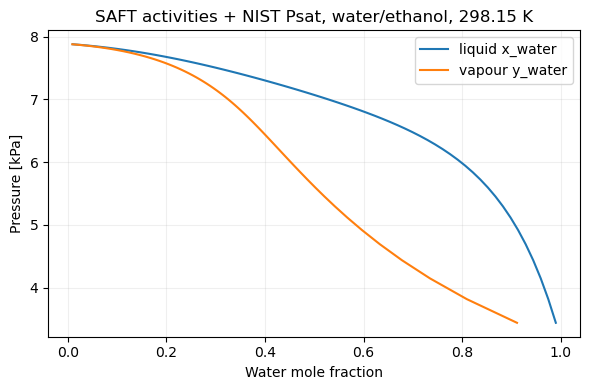

In [2]:
xs=np.linspace(.01,.99,65)
points=[bubble_pressure(model,[v,1-v],T,psat) for v in xs]
pressures=np.array([p.pressure_Pa for p in points])/1000
y=np.array([p.vapor_composition[0] for p in points])
fig,ax=plt.subplots(figsize=(6,4))
ax.plot(xs,pressures,label='liquid x_water');ax.plot(y,pressures,label='vapour y_water')
ax.set(xlabel='Water mole fraction',ylabel='Pressure [kPa]',title='SAFT activities + NIST Psat, water/ethanol, 298.15 K')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();plt.show()

The curves are model predictions. The pressure/dew round trip checks the
implementation, not agreement with measured VLE. For another temperature,
select correlations within their documented ranges. To use COSMO-RS, construct
its real adapter as in notebook 09 and pass it to the same bubble/dew calls.